# 03: DROZY, two label types on identical recordings

FatigueSet on its own could not separate three explanations for its null result: the hardware, the labels, or the evaluation. DROZY was brought in under a pre-registration locked before the data was downloaded, because it holds two of those fixed. It is clinical polysomnography EEG recorded under sleep deprivation, and every recording carries two independent labellings: how sleepy the participant said they were (KSS), and how they actually performed on a vigilance task (reaction-time lapses). Same EEG, same frozen pipeline, two label types. If the answer changes when only the labels change, the labels were the story.

Evaluation is leave-one-participant-out only. In DROZY the session order is the deprivation order, so any session-based split is confounded by construction. 13 of the 14 recorded participants are analysed; one has a single session and cannot form a within-person contrast.

## 0. Setup

In [1]:
# Setup. The pipeline in src/ is the engine; this notebook is a front door
# to it. Here I find the repository root, put the frozen modules and the
# pinned libraries on the path, and patch one NumPy rename.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if not hasattr(np, "trapz"):
    # NumPy 2.x renamed trapz to trapezoid. The frozen band-power module
    # still calls np.trapz, so I alias it here instead of editing frozen code.
    np.trapz = np.trapezoid


def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "features" / "bandpower.py").exists():
            return cand
    raise FileNotFoundError("repository root not found above the working directory")


ROOT = find_root()
for extra in (str(ROOT), str(Path.home() / "workspace" / ".pylibs")):
    if Path(extra).exists() and extra not in sys.path:
        sys.path.insert(0, extra)

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
PROC = ROOT / "data" / "processed"
pd.set_option("display.width", 120)
print("repository root:", ROOT)

repository root: /home/hatch/workspace/thesis-fatigue


## 1. The two labellings

For each participant I take the session with the lowest value as alert and the session with the highest value as fatigued, and I exclude the middle session. In the KSS arm the ranking is by Karolinska Sleepiness Scale score; in the RT arm the same sessions are ranked by PVT lapse rate (the share of responses slower than 500 ms) instead. The feature set, the model and the folds are the Week 2 pipeline unchanged; only the labels move. The all-channel set uses all five PSG channels; the Fz-only set is the declared single-channel comparison.

In [2]:
drozy = pd.read_csv(TAB / "drozy_lopo_aggregate.csv")
main = drozy[drozy.combo.isin(["kss_all", "kss_fz", "rt_all", "rt_fz"])]
main[["combo", "n_participants", "balanced_accuracy", "ba_ci95_low", "ba_ci95_high",
      "roc_auc", "p_value_ge_real"]]

,combo,n_participants,balanced_accuracy,ba_ci95_low,ba_ci95_high,roc_auc,p_value_ge_real
0,kss_all,13,0.602203,0.563079,0.644354,0.680502,0.004975
1,kss_fz,13,0.542553,0.504535,0.582394,0.597335,0.134328
2,rt_all,13,0.482389,0.420844,0.549103,0.476885,0.726368
3,rt_fz,13,0.467481,0.413574,0.526638,0.461957,0.810945


In [3]:
pd.read_csv(TAB / "drozy_paired_contrast.csv")

,contrast,n_participants,mean_difference,ci95_low,ci95_high,bootstrap_share_above_zero
0,"BA(KSS all-channel) - BA(RT all-channel), pair...",13,0.119813,0.061536,0.178608,1.0


## 2. What came out

The locked headline, in the exploratory framing this result is reported in:

**KSS-extreme labels were decodable across participants; RT-extreme labels from the same recordings were not; this contrast is not isolated from session order and rests on a small disagreeing subset.**

Subjective labels transfer (0.602 [0.563, 0.644], p = 0.005); performance labels on the same recordings do not (0.482 [0.421, 0.549], p = 0.726); the paired difference is +0.120 [0.062, 0.179]. Two cautions travel with these numbers everywhere: the two arms pick a different fatigued session for 4 of the 13 participants, and about 60% of the paired contrast is carried by those four; and KSS is correlated with session order, which this design cannot fully isolate.

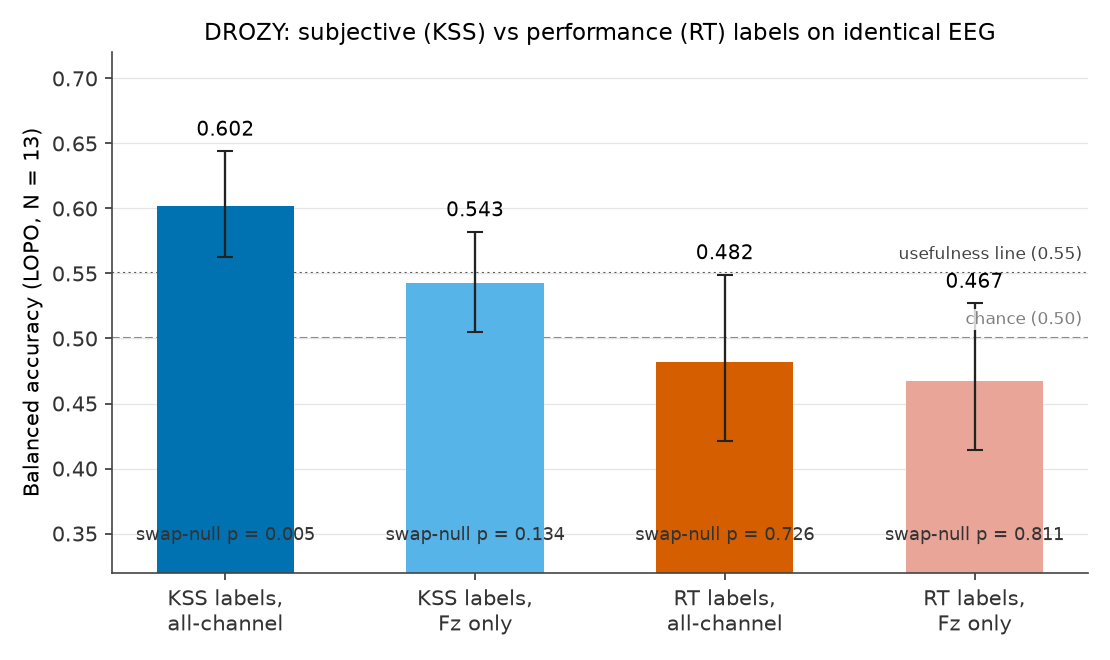

In [4]:
from IPython.display import Image

Image(filename=str(FIG / "fig_drozy_dissociation.png"))

## 3. The positive control: pricing the RT null

A flat RT result means one of two things: there is no RT-linked signal of useful size, or the test cannot see one. The control separates those. I take the DROZY windows, permute the labels within each participant (so any real label structure is destroyed), inject a known theta and alpha power increase into the windows the permuted labels call fatigued, and ask whether the frozen pipeline recovers it. The dose ladder runs from no injection to the full Week 2 size (theta power x2.0, alpha power x1.5) in steps of 0.25, with five repeats per dose.

The KSS arm had a gate to pass, set in advance: recovery of at least 0.75 at full dose and at least 0.60 at half dose, mirroring the FatigueSet recovery pattern. For the RT arm the ladder prices the null: the smallest dose the control reliably detects (in at least 4 of 5 repeats) is the smallest RT-linked effect size the flat result can speak about.

In [5]:
pc = pd.read_csv(TAB / "drozy_poscontrol_permuted.csv")
ladder = (pc.groupby(["arm", "dose"])
            .agg(recovery_mean=("recovery_ba", "mean"),
                 recovery_min=("recovery_ba", "min"),
                 recovery_max=("recovery_ba", "max"),
                 repeats_detected=("detected", "sum"),
                 repeats=("detected", "size"))
            .reset_index())
ladder

,arm,dose,recovery_mean,recovery_min,recovery_max,repeats_detected,repeats
0,kss,0.00,0.488701,0.452915,0.530321,0,5
1,kss,0.25,0.574838,0.520443,0.595769,3,5
2,kss,0.50,0.671539,0.640466,0.690567,5,5
3,kss,0.75,0.744383,0.725490,0.759290,5,5
4,kss,1.00,0.798491,0.778017,0.816696,5,5
5,rt,0.00,0.504860,0.459536,0.535579,0,5
6,rt,0.25,0.582900,0.537906,0.615266,3,5
7,rt,0.50,0.659989,0.620448,0.689567,5,5
8,rt,0.75,0.730795,0.702974,0.754842,5,5
9,rt,1.00,0.782882,0.762328,0.806297,5,5


In [6]:
kss = ladder[ladder.arm == "kss"].set_index("dose")
gate = (kss.loc[1.0, "recovery_mean"] >= 0.75) and (kss.loc[0.5, "recovery_mean"] >= 0.60)
print(f"KSS gate: full dose {kss.loc[1.0, 'recovery_mean']:.3f} (bar 0.75), "
      f"half dose {kss.loc[0.5, 'recovery_mean']:.3f} (bar 0.60) -> {'PASS' if gate else 'FAIL'}")

rt = ladder[ladder.arm == "rt"]
detected = rt[rt.repeats_detected >= 4]
print(f"RT arm: reliably detected from dose {detected.dose.min():.2f} upward "
      f"(at dose 0.25 only {int(rt[rt.dose == 0.25].repeats_detected.iloc[0])} of 5 repeats detected)")

KSS gate: full dose 0.798 (bar 0.75), half dose 0.672 (bar 0.60) -> PASS
RT arm: reliably detected from dose 0.50 upward (at dose 0.25 only 3 of 5 repeats detected)


## 4. How I read this

The gate passed, so the pipeline demonstrably sees an injected effect of the Week 2 size on DROZY channels; the RT null is not a broken test. But the control establishes reliable detection only at dose 0.5 and above on its 0.25-step grid, so smaller RT-related band-power changes are not ruled out, and the dose scale, calibrated on label-permuted data, is not mapped onto the observed KSS score. The dissociation is pipeline-specific and sensitivity-bounded, and it is reported as exploratory: the pipeline was pre-registered, but this outcome pattern was not one of the pre-declared rows. One pre-registered row is deliberately not claimed: the KSS score sits +0.094 above the FatigueSet LOPO score, under the 0.10 line set in advance for calling the cross-dataset difference clearly interpretable.

Full write-ups: `docs/drozy_results.md` and `docs/drozy_positive_control.md`. The pre-registration, locked before download: `docs/dataset2_preregistration.md`.